# 🕵️‍♂️ Pakistani Social Media Content Detective
## Step 3: Sentiment analysis

**On your computer (VS Code):** install the packages once with `python3 -m pip install -r requirements.txt`, and make sure `comments_clean.csv` is in this folder (Step 3 saves it here).

**Speed tip (optional, Colab only):** click **Runtime → Change runtime type → T4 GPU → Save** before running. It makes Cell 3 about 10x faster. Without it, it still works, just slower. On a Mac with Apple Silicon (M1/M2/M3...), the Mac's GPU is used automatically.

Run the cells in order.

### Cell 1: Load comments_clean.csv (on Colab, upload it when asked)

In [8]:
import pandas as pd

# On Colab, upload the file. On your computer, it is read from this folder.
try:
    from google.colab import files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    uploaded = files.upload()
comments = pd.read_csv("comments_clean.csv")
print(f"Loaded {len(comments)} clean comments")

Loaded 7915 clean comments


### Cell 2: Load the AI sentiment model
We use **XLM-RoBERTa** (`cardiffnlp/twitter-xlm-roberta-base-sentiment`), a free multilingual model trained on social media text. It labels text as positive, neutral, or negative. The first run downloads it (about 1 GB), which takes a minute or two.

In [9]:
from transformers import pipeline
import torch

# Use a GPU if there is one: NVIDIA on Colab, or Apple Silicon on a Mac
if torch.cuda.is_available():
    device = 0
elif torch.backends.mps.is_available():
    device = "mps"
else:
    device = -1

sentiment_model = pipeline(
    "sentiment-analysis",
    model="cardiffnlp/twitter-xlm-roberta-base-sentiment",
    device=device,
)

# Quick test
tests = ["Zabardast gari hai, love it!", "Bohat mehngi hai, bekar car", "Price kya hai?"]
for text, result in zip(tests, sentiment_model(tests)):
    print(f"{text}  ->  {result['label']} ({result['score']:.2f})")

Loading weights: 100%|██████████| 201/201 [00:00<00:00, 39661.98it/s]


Zabardast gari hai, love it!  ->  positive (0.83)
Bohat mehngi hai, bekar car  ->  positive (0.36)
Price kya hai?  ->  neutral (0.60)


### Cell 3: Label every comment (takes a few minutes)

In [10]:
LABEL_FIX = {"label_0": "negative", "label_1": "neutral", "label_2": "positive"}

results = sentiment_model(
    comments["comment"].tolist(), batch_size=32, truncation=True, max_length=128
)
labels = [r["label"].lower() for r in results]
comments["sentiment"] = [LABEL_FIX.get(l, l) for l in labels]
comments["confidence"] = [round(r["score"], 2) for r in results]

print("Sentiment counts:")
print(comments["sentiment"].value_counts())
print("\nSentiment percentages:")
print((comments["sentiment"].value_counts(normalize=True) * 100).round(1))

Sentiment counts:
sentiment
negative    2933
neutral     2648
positive    2334
Name: count, dtype: int64

Sentiment percentages:
sentiment
negative    37.1
neutral     33.5
positive    29.5
Name: proportion, dtype: float64


### Cell 4: The big question: which sentiment drives more interaction?
Interaction = likes and replies on a comment.

           avg_likes_per_comment  avg_replies_per_comment
sentiment                                                
negative                    1.59                     0.42
neutral                     1.43                     0.37
positive                    2.99                     0.37


<Axes: title={'center': 'Average interaction by comment sentiment'}, xlabel='sentiment'>

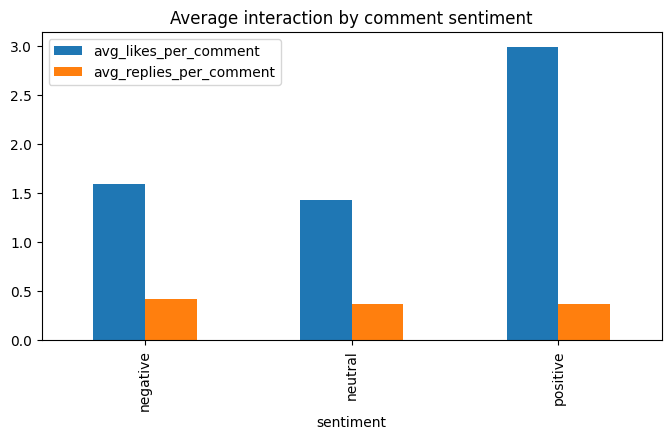

In [11]:
interaction = comments.groupby("sentiment")[["comment_likes", "replies"]].mean().round(2)
interaction.columns = ["avg_likes_per_comment", "avg_replies_per_comment"]
print(interaction)

interaction.plot(kind="bar", figsize=(8, 4), title="Average interaction by comment sentiment")

### Cell 5: Sentiment by language

sentiment   negative  neutral  positive
language                               
English         30.5     37.1      32.4
Roman Urdu      46.9     27.6      25.5
Urdu            44.1     33.7      22.2


<Axes: title={'center': 'Sentiment % by language'}, xlabel='language'>

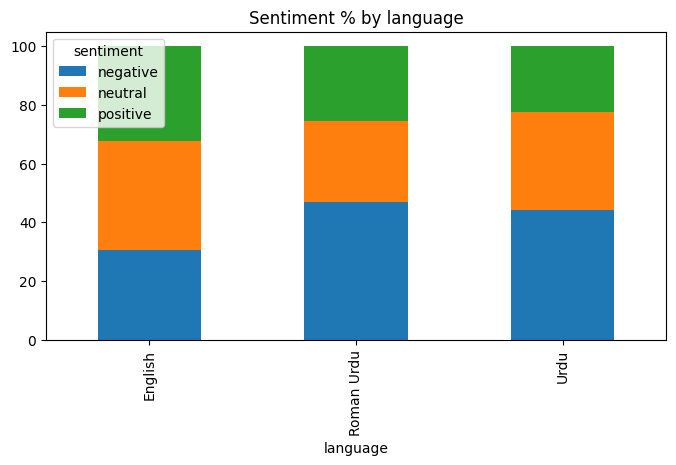

In [12]:
by_language = pd.crosstab(comments["language"], comments["sentiment"], normalize="index") * 100
print(by_language.round(1))

by_language.plot(kind="bar", stacked=True, figsize=(8, 4), title="Sentiment % by language")

### Cell 6: Check the AI's accuracy yourself (important for your report!)
This shows 30 random comments with the AI's label. Read each one and count how many labels you agree with.

**Accuracy = (number correct ÷ 30) × 100.** For example, 24 correct = 80% accuracy. Put this number in your report.

In [13]:
check = comments.sample(min(30, len(comments)), random_state=42)[["comment", "sentiment"]]
pd.set_option("display.max_colwidth", 120)
check

,comment,sentiment
4894,"Honestly, a lot of things are missing in the Pakistani H6 GT: No Alcantara seats No paddle shifters, even though it ...",negative
7241,"After 5 years, there is a possibility N One and Bingua will be at sale price to resale",neutral
1677,price honi chaye the max 2.1 2.2 with all texes. too much costly i think so. (1.77 CR ki china ma chlo tax dal kar b...,negative
1964,In China it is around 12k $,neutral
3025,Fuel consumption kitna hy,neutral
6256,Dude this looks ugly 🥴🥴,negative
6302,gari leak horahi hai 07:24,neutral
2436,Arfan Bhai such a nice guy,positive
4526,Mg ki phev bi to itne men mil jati ha wo q nahi li,negative
2464,Bacha apna sabak bhool geya tha😂😂😂😂,negative


### Cell 7: Save your results

In [ ]:
comments.to_csv("comments_with_sentiment.csv", index=False, encoding="utf-8-sig")
if IN_COLAB:
    files.download("Step-3_comments_with_sentiment.csv")
print("Saved! We'll use this file in Step 5.")

Saved! We'll use this file in Step 5.


### Cell 8: Sentiment for a single video
Type part of a video's title in `VIDEO_SEARCH` (for example `"Tiggo 9"`) and run the cell. It shows that video's sentiment next to the average of all videos, with its own chart.

If several videos match, the cell lists them. Set `VIDEO_NUMBER` to the one you want and run it again. (Cells 1–3 must have run first.)

Videos matching "Tiggo 9":
                                                                                           title  comments
1  Chery Tiggo 9  | 600+ HP, 20-Inch Rims & Real Ownership Experience | Owner’s Review Pakwheels        22

Showing video #1: Chery Tiggo 9  | 600+ HP, 20-Inch Rims & Real Ownership Experience | Owner’s Review Pakwheels
Views: 66,145  |  Likes: 573  |  Comments analysed: 22
Note: fewer than 30 comments, so a few comments can change these percentages a lot.

           comments  this_video_%  all_videos_%  avg_likes_per_comment
sentiment                                                             
negative          7          31.8          37.1                    1.1
neutral           9          40.9          33.5                    2.3
positive          6          27.3          29.5                    0.8


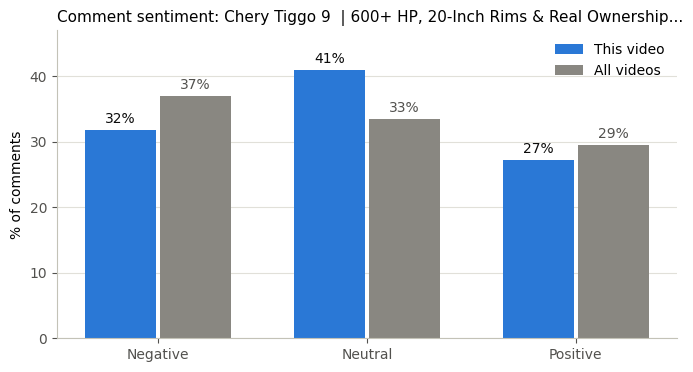

In [16]:
VIDEO_SEARCH = "Tiggo 9"   # any part of the video title (capital letters don't matter)
VIDEO_NUMBER = 1           # if several videos match, pick one from the list this cell prints

import matplotlib.pyplot as plt

SENTIMENTS = ["negative", "neutral", "positive"]

# 1) Find the videos whose title contains VIDEO_SEARCH
matches = (
    comments[comments["title"].str.contains(VIDEO_SEARCH, case=False, regex=False, na=False)]
    .groupby(["video_id", "title"]).size()
    .sort_values(ascending=False)
    .reset_index(name="comments")
)
if matches.empty:
    raise ValueError(f'No video title contains "{VIDEO_SEARCH}". Try a shorter search, e.g. just "Tiggo".')
matches.index = range(1, len(matches) + 1)
print(f'Videos matching "{VIDEO_SEARCH}":')
print(matches[["title", "comments"]].to_string())
if VIDEO_NUMBER not in matches.index:
    raise ValueError(f"VIDEO_NUMBER must be between 1 and {len(matches)}.")

# 2) Sentiment of this video compared with all videos
video = comments[comments["video_id"] == matches.loc[VIDEO_NUMBER, "video_id"]]
title = video["title"].iloc[0]
print(f"\nShowing video #{VIDEO_NUMBER}: {title}")
print(f"Views: {video['video_views'].iloc[0]:,}  |  Likes: {video['video_likes'].iloc[0]:,}  |  Comments analysed: {len(video)}")
if len(video) < 30:
    print("Note: fewer than 30 comments, so a few comments can change these percentages a lot.")

summary = pd.DataFrame({
    "comments": video["sentiment"].value_counts(),
    "this_video_%": video["sentiment"].value_counts(normalize=True) * 100,
    "all_videos_%": comments["sentiment"].value_counts(normalize=True) * 100,
    "avg_likes_per_comment": video.groupby("sentiment")["comment_likes"].mean(),
}).reindex(SENTIMENTS).fillna(0)
summary["comments"] = summary["comments"].astype(int)
print()
print(summary.round(1))

# 3) Chart: this video (blue) next to all videos (gray)
x = range(len(SENTIMENTS))
fig, ax = plt.subplots(figsize=(8, 4))
this_bars = ax.bar([i - 0.18 for i in x], summary["this_video_%"], width=0.34, color="#2a78d6", label="This video")
all_bars = ax.bar([i + 0.18 for i in x], summary["all_videos_%"], width=0.34, color="#898781", label="All videos")
ax.bar_label(this_bars, fmt="%.0f%%", padding=3, color="#0b0b0b")
ax.bar_label(all_bars, fmt="%.0f%%", padding=3, color="#52514e")
ax.set_xticks(list(x), [s.capitalize() for s in SENTIMENTS])
ax.set_ylabel("% of comments")
ax.set_ylim(0, max(summary["this_video_%"].max(), summary["all_videos_%"].max()) * 1.15)
ax.set_title(f"Comment sentiment: {title[:55] + '...' if len(title) > 55 else title}", loc="left", fontsize=11)
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color("#c3c2b7")
ax.tick_params(colors="#52514e")
ax.grid(axis="y", color="#e1e0d9", linewidth=0.8)
ax.set_axisbelow(True)
plt.show()